In [23]:
import torch
import torchvision
import torchvision.transforms as transforms
import torch.nn as nn

# ==========================================
# 1. PREPARACIÓN DE DATOS Y MODELO
# ==========================================
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.4914, 0.4822, 0.4465], std=[0.2023, 0.1994, 0.201])
])

print("Descargando/Cargando datasets...")
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
# Usamos el testloader para la evaluación del ataque
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False, num_workers=2)

print("Cargando el modelo cifar10_resnet20...")
model = torch.hub.load("chenyaofo/pytorch-cifar-models", "cifar10_resnet20", pretrained=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print("-" * 30)
print(f"✅ Dispositivo configurado: {device}")
print(f"✅ Tamaño del dataset de test: {len(testset)} imágenes")
print("-" * 30)

Descargando/Cargando datasets...


/home/anton/Escritorio/GIA-Apuntes/4º curso/2º cuatri/slesi/practicas/Slesi/.venv/lib/python3.12/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Cargando el modelo cifar10_resnet20...
------------------------------
✅ Dispositivo configurado: cpu
✅ Tamaño del dataset de test: 10000 imágenes
------------------------------


Using cache found in /home/anton/.cache/torch/hub/chenyaofo_pytorch-cifar-models_master


In [24]:
def fgsm_attack(images, epsilon, data_grad):
    # 1. Obtener el signo de los gradientes
    sign_data_grad = data_grad.sign()
    
    # 2. Crear la imagen adversaria añadiendo la perturbación
    perturbed_images = images + epsilon * sign_data_grad
    
    # Nota: Debido a la normalización estricta de CIFAR-10, omitimos el "clipping" a [0,1] 
    # en el espacio normalizado, ya que alteraría los rangos estandarizados reales.
    return perturbed_images

def evaluate_evasion_attack(model, testloader, epsilon, min_images=1000):
    print(f"Iniciando evaluación de FGSM (epsilon = {epsilon})...")
    
    # El modelo debe estar en modo evaluación
    model.eval()
    criterion = nn.CrossEntropyLoss()
    
    correct_clean = 0
    correct_adv = 0
    total = 0
    
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)
        
        # --- A. PRECISION ORIGINAL (Limpia) ---
        # No necesitamos gradientes para evaluar las imágenes originales
        with torch.no_grad():
            outputs_clean = model(images)
            _, predicted_clean = torch.max(outputs_clean.data, 1)
            correct_clean += (predicted_clean == labels).sum().item()
            
        # --- B. ATAQUE ADVERSARIO ---
        # Habilitamos el cálculo de gradientes para las imágenes de entrada
        images.requires_grad = True
        
        # Forward pass para obtener gradientes
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # Limpiar gradientes previos del modelo
        model.zero_grad()
        
        # Backward pass para calcular los gradientes de la imagen
        loss.backward()
        
        # Extraer los gradientes de las imágenes
        data_grad = images.grad.data
        
        # Generar las imágenes adversarias
        perturbed_images = fgsm_attack(images, epsilon, data_grad)
        
        # --- C. PRECISION ADVERSARIA ---
        # Evaluamos el modelo de nuevo usando las imágenes manipuladas
        with torch.no_grad():
            outputs_adv = model(perturbed_images)
            _, predicted_adv = torch.max(outputs_adv.data, 1)
            correct_adv += (predicted_adv == labels).sum().item()
            
        total += labels.size(0)
        
        # Detener la evaluación si ya superamos el mínimo requerido (1000)
        if total >= min_images:
            break
        # Calcular métricas finales
    clean_acc = 100 * correct_clean / total
    adv_acc = 100 * correct_adv / total
    
    print("=" * 30)
    print(f"📊 Resultados sobre {total} imágenes:")
    print(f"Precisión Limpia (Sin ataque): {clean_acc:.2f}%")
    print(f"Precisión Adversa (Con FGSM):  {adv_acc:.2f}%")
    print(f"Caída de precisión:            {clean_acc - adv_acc:.2f}%")
    print("=" * 30)

epsilon_value = 0.05
evaluate_evasion_attack(model, testloader, epsilon=epsilon_value, min_images=1000)

Iniciando evaluación de FGSM (epsilon = 0.05)...
📊 Resultados sobre 1024 imágenes:
Precisión Limpia (Sin ataque): 92.68%
Precisión Adversa (Con FGSM):  21.39%
Caída de precisión:            71.29%


In [25]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from art.estimators.classification import PyTorchClassifier
from art.attacks.evasion import ProjectedGradientDescent

# Asumiendo que ya tienes 'model', 'testloader' y 'device' del código anterior

def evaluate_pgd_with_art(model, testloader, epsilon, min_images=1000):
    print(f"Configurando PGD mediante ART (epsilon = {epsilon})...")
    
    # 1. Preparar el modelo para ART
    model.eval()
    criterion = nn.CrossEntropyLoss()
    # ART requiere un optimizador en su constructor por diseño de su API, 
    # aunque para ataques de evasión en inferencia no se usa para entrenar.
    optimizer = optim.Adam(model.parameters(), lr=0.01)
    
    # Envolvemos el modelo de PyTorch en el clasificador de ART
    classifier = PyTorchClassifier(
        model=model,
        loss=criterion,
        optimizer=optimizer,
        input_shape=(3, 32, 32), # Dimensión de las imágenes CIFAR-10
        nb_classes=10,
        device_type='gpu' if torch.cuda.is_available() else 'cpu'
    )
    
    # 2. Configurar el ataque PGD
    # eps: Magnitud máxima de la perturbación (igual que en FGSM)
    # eps_step: Tamaño del paso en cada iteración (suele ser eps / (iteraciones/2) o similar)
    # max_iter: Número de iteraciones del ataque
    attack_pgd = ProjectedGradientDescent(
        estimator=classifier,
        eps=epsilon,
        eps_step=epsilon/4, 
        max_iter=10,
        batch_size=64,
        targeted=False
    )
    
    # 3. Bucle de evaluación
    correct_clean = 0
    correct_adv = 0
    total = 0
    
    print("Generando ejemplos adversarios y evaluando...")
    
    for images, labels in testloader:
        # ART trabaja nativamente con arrays de NumPy, así que convertimos los tensores
        images_np = images.cpu().numpy()
        labels_np = labels.cpu().numpy()
        
        # --- A. PRECISIÓN ORIGINAL ---
        # Predicciones limpias usando la API de ART
        preds_clean = classifier.predict(images_np)
        correct_clean += np.sum(np.argmax(preds_clean, axis=1) == labels_np)
        
        # --- B. GENERACIÓN DEL ATAQUE ---
        # ART se encarga de todo el proceso iterativo interno
        images_adv_np = attack_pgd.generate(x=images_np)
        
        # --- C. PRECISIÓN ADVERSARIA ---
        preds_adv = classifier.predict(images_adv_np)
        correct_adv += np.sum(np.argmax(preds_adv, axis=1) == labels_np)
        
        total += len(labels_np)
        
        # Imprimir progreso para saber que no se ha quedado colgado
        print(f"Procesadas {total} imágenes...", end='\r')
        
        if total >= min_images:
            break

    # 4. Resultados
    clean_acc = 100 * correct_clean / total
    adv_acc = 100 * correct_adv / total
    
    print("\n" + "=" * 40)
    print(f"📊 Resultados PGD (ART) sobre {total} imágenes:")
    print(f"Iteraciones (max_iter):        10")
    print(f"Tamaño de paso (eps_step):     {epsilon/4:.4f}")
    print(f"Precisión Limpia (Sin ataque): {clean_acc:.2f}%")
    print(f"Precisión Adversa (Con PGD):   {adv_acc:.2f}%")
    print(f"Caída de precisión:            {clean_acc - adv_acc:.2f}%")
    print("=" * 40)

# Ejecutar la evaluación (mantenemos el epsilon de 0.05 para poder comparar con FGSM)
evaluate_pgd_with_art(model, testloader, epsilon=0.05, min_images=1000)

Configurando PGD mediante ART (epsilon = 0.05)...
Generando ejemplos adversarios y evaluando...


Procesadas 1024 imágenes...
📊 Resultados PGD (ART) sobre 1024 imágenes:
Iteraciones (max_iter):        10
Tamaño de paso (eps_step):     0.0125
Precisión Limpia (Sin ataque): 92.68%
Precisión Adversa (Con PGD):   5.57%
Caída de precisión:            87.11%



Iniciando evaluación comparativa (ASR vs Epsilon)...

➡️ Evaluando Epsilon: 0.0

➡️ Evaluando Epsilon: 0.01


<>:130: SyntaxWarning: invalid escape sequence '\e'
<>:131: SyntaxWarning: invalid escape sequence '\e'
<>:130: SyntaxWarning: invalid escape sequence '\e'
<>:131: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_10870/2641255491.py:130: SyntaxWarning: invalid escape sequence '\e'
  plt.title('Tasa de Éxito (ASR) vs Presupuesto de Perturbación ($\epsilon$)', fontsize=14, fontweight='bold', pad=15)
/tmp/ipykernel_10870/2641255491.py:131: SyntaxWarning: invalid escape sequence '\e'
  plt.xlabel('Presupuesto de Perturbación ($\epsilon$) en norma $L_\infty$', fontsize=12)
                                                            

   ASR FGSM: 33.19% | ASR PGD: 46.89%

➡️ Evaluando Epsilon: 0.025


   ASR FGSM: 61.12% | ASR PGD: 92.62%

➡️ Evaluando Epsilon: 0.05


   ASR FGSM: 76.92% | ASR PGD: 100.00%

➡️ Evaluando Epsilon: 0.075


   ASR FGSM: 82.19% | ASR PGD: 100.00%

➡️ Evaluando Epsilon: 0.1


   ASR FGSM: 83.77% | ASR PGD: 100.00%

➡️ Evaluando Epsilon: 0.15


   ASR FGSM: 85.46% | ASR PGD: 100.00%

➡️ Evaluando Epsilon: 0.2


   ASR FGSM: 85.67% | ASR PGD: 100.00%


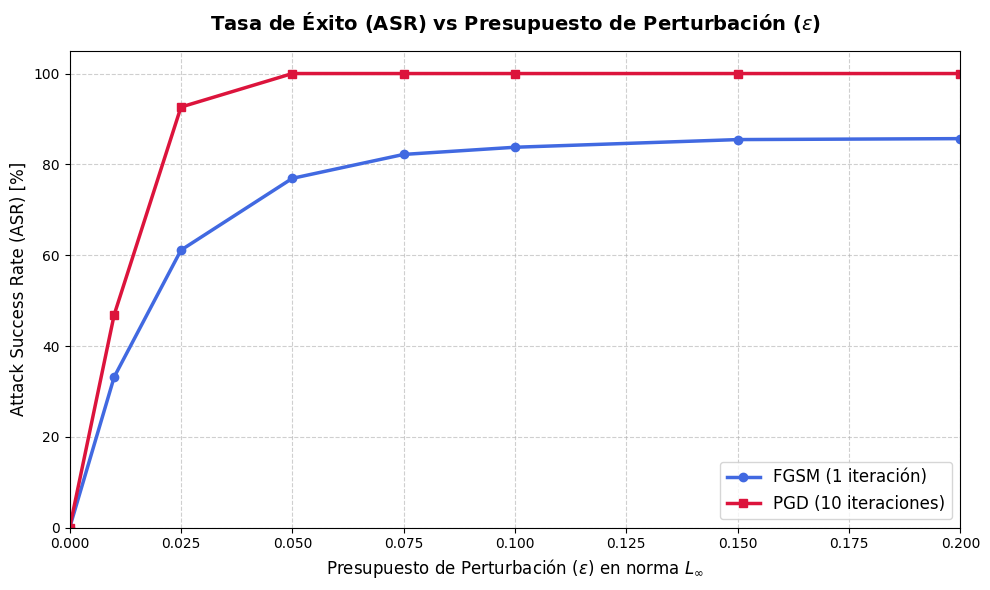

In [26]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from art.attacks.evasion import ProjectedGradientDescent
from art.estimators.classification import PyTorchClassifier

# Asumimos que 'model', 'testloader', 'device' y 'fgsm_attack' ya están en memoria

def generate_asr_curve(model, testloader, epsilons, min_images=1000):
    print("\n" + "="*50)
    print("Iniciando evaluación comparativa (ASR vs Epsilon)...")
    print("="*50)
    
    model.eval()
    criterion = nn.CrossEntropyLoss()
    
    # 1. Configurar el clasificador base de ART (fuera del bucle para no repetir)
    optimizer = optim.Adam(model.parameters(), lr=0.01)
    classifier = PyTorchClassifier(
        model=model,
        loss=criterion,
        optimizer=optimizer,
        input_shape=(3, 32, 32),
        nb_classes=10,
        device_type='gpu' if torch.cuda.is_available() else 'cpu'
    )
    
    asr_fgsm_list = []
    asr_pgd_list = []
    
    # 2. Bucle principal sobre los presupuestos de perturbación
    for eps in epsilons:
        print(f"\n➡️ Evaluando Epsilon: {eps}")
        
        # Si eps es 0, no hay ataque, el ASR es 0% por definición
        if eps == 0.0:
            asr_fgsm_list.append(0.0)
            asr_pgd_list.append(0.0)
            continue
            
        # Instanciar PGD para el epsilon actual (10 iteraciones es estándar)
        attack_pgd = ProjectedGradientDescent(
            estimator=classifier, eps=eps, eps_step=eps/4, max_iter=10, batch_size=64, targeted=False
        )
        
        successful_fgsm = 0
        successful_pgd = 0
        total_correct_clean = 0
        processed = 0
        
        # 3. Bucle de evaluación sobre el dataset
        for images, labels in testloader:
            images, labels = images.to(device), labels.to(device)
            
            # --- A. Predicciones Limpias (Baseline) ---
            images.requires_grad = True
            outputs_clean = model(images)
            _, preds_clean = torch.max(outputs_clean, 1)
            
            # Máscara lógica de imágenes correctamente clasificadas
            correct_mask = (preds_clean == labels)
            total_correct_clean += correct_mask.sum().item()
            
            # --- B. Ataque FGSM ---
            loss = criterion(outputs_clean, labels)
            model.zero_grad()
            loss.backward()
            data_grad = images.grad.data
            
            # Generar y evaluar
            images_fgsm = fgsm_attack(images, eps, data_grad)
            with torch.no_grad():
                outputs_fgsm = model(images_fgsm)
                _, preds_fgsm = torch.max(outputs_fgsm, 1)
            
            # Contar éxito: modelo se equivoca AHORA, pero acertó ANTES
            successful_fgsm += ((preds_fgsm != labels) & correct_mask).sum().item()
            
            # --- C. Ataque PGD (ART) ---
            # Pasar a NumPy para ART
            images_np = images.detach().cpu().numpy()
            labels_np = labels.cpu().numpy()
            correct_mask_np = correct_mask.cpu().numpy()
            
            # Generar y evaluar
            images_pgd_np = attack_pgd.generate(x=images_np)
            preds_pgd_np = np.argmax(classifier.predict(images_pgd_np), axis=1)
            
            # Contar éxito PGD
            successful_pgd += np.sum((preds_pgd_np != labels_np) & correct_mask_np)
            
            processed += labels.size(0)
            if processed >= min_images:
                break
                
        # --- D. Cálculo del ASR Final para este Epsilon ---
        # ASR = (Ataques Exitosos / Total Imágenes Originalmente Correctas) * 100
        asr_fgsm = (successful_fgsm / total_correct_clean) * 100.0 if total_correct_clean > 0 else 0
        asr_pgd = (successful_pgd / total_correct_clean) * 100.0 if total_correct_clean > 0 else 0
        
        asr_fgsm_list.append(asr_fgsm)
        asr_pgd_list.append(asr_pgd)
        
        print(f"   ASR FGSM: {asr_fgsm:.2f}% | ASR PGD: {asr_pgd:.2f}%")
        
    return epsilons, asr_fgsm_list, asr_pgd_list

# ==========================================
# EJECUCIÓN Y GENERACIÓN DE LA GRÁFICA
# ==========================================
# Definimos el rango de presupuestos L_infinito a evaluar
epsilons_to_test = [0.0, 0.01, 0.025, 0.05, 0.075, 0.1, 0.15, 0.2]

# Obtener los datos (esto puede tardar unos minutos debido a las iteraciones de PGD)
eps_vals, asr_fgsm_vals, asr_pgd_vals = generate_asr_curve(
    model, testloader, epsilons_to_test, min_images=1000
)

# Configuración visual con Matplotlib
plt.figure(figsize=(10, 6))

# Plotear ambas curvas
plt.plot(eps_vals, asr_fgsm_vals, marker='o', linewidth=2.5, color='royalblue', label='FGSM (1 iteración)')
plt.plot(eps_vals, asr_pgd_vals, marker='s', linewidth=2.5, color='crimson', label='PGD (10 iteraciones)')

# Detalles estéticos de la gráfica
plt.grid(True, linestyle='--', alpha=0.6)
plt.title('Tasa de Éxito (ASR) vs Presupuesto de Perturbación ($\epsilon$)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Presupuesto de Perturbación ($\epsilon$) en norma $L_\infty$', fontsize=12)
plt.ylabel('Attack Success Rate (ASR) [%]', fontsize=12)
plt.legend(fontsize=12, loc='lower right')

# Ajustar límites de los ejes
plt.xlim(0, max(eps_vals))
plt.ylim(0, 105)

plt.tight_layout()
# Descomenta la siguiente línea si quieres guardar la imagen en tu disco duro
# plt.savefig('grafica_asr_comparativa.png', dpi=300)
plt.show()